# Analysis of the Behavior of the E-FCFW Algorithm

**Abstract.** E-FCFW [1, 2] approximates a demand matrix $D^*$ by a sparse convex combination of matchings,
$D^*\approx\sum_l\alpha_lP_l$, minimizing the error $f=\|D-D^*\|_F^2/n^2$. In [2], QAOA samples candidate matchings
from a QUBO on each partition of the residual graph, and greedy repair makes the samples valid matchings.

*What this work adds.* (1) QAOA is replaced by classical samplers: Goemans–Williamson with local search (GW+LS) [3],
and MIP, the exact 10 best solutions of each QUBO. (2) Every non-quantum experiment of [1, 2] is re-run with them.
(3) The study of [2] is extended by an 18-graph benchmark repeated with 10 random seeds, two variants of the repair
step, and a Boltzmann-shaped sampler.

*Takeaways.* (1) The classical steps around the sampler decide the result: without repair, $f$ stalls at
$2\text{–}4\times10^{-5}$ instead of reaching $10^{-6}$, and partitions with $p_s=20$ instead of $50$ raise $f$ by
about 40%. (2) The sampler only has to be structured: uniform samples raise $f$ by 36–46%, while GW+LS, SA and the
exact MIP differ by at most 7%. Solving the QUBO better does not give a better decomposition. (3) No partitioned
sampler beats FCFW, which uses no sampler; adding a maximum-weight matching on the cut edges improves every structured
sampler by 2–7% and largely closes this gap (SA reaches FCFW). (4) GW+LS comes within 6% of SA at about a ninth of its runtime. A quantum sampler is
therefore unlikely to improve this pipeline through better QUBO solutions; the gains lie in the repair and in the cut
edges.

**Key results** (2026 setting unless stated otherwise):

1. **Repair is essential.** Without greedy repair, the decomposition of PEGASE-1354 stalls at errors of
   $2\text{–}4\times10^{-5}$; with repair, the target error $\varepsilon=10^{-6}$ is reached with 10 or 11 matchings
   (Sec. 6.2).
2. **Structured samples are needed, an optimal sampler is not.** Uniform random sampling yields a 36–46% higher
   error than the structured samplers (18 graphs, 10 seeds). Among the structured samplers, GW+LS, SA and MIP lie
   within 7% of each other. SA is slightly but consistently best (lowest mean error in 8 of 10 seeds), while on
   individual instances each of them is best about equally often (Sec. 7.2).
3. **No sampler beats the global maximum-weight matching alone.** With the repair step of [2], every partitioned
   sampler ends 6–14% above the error of the unpartitioned FCFW, which uses no sampler at all (Sec. 7.2).
4. **The cut edges matter as much as the sampler.** Adding a maximum-weight matching on the cut edges between free
   nodes lowers the error of every structured sampler in every seed, by 2–7%, comparable to the spread between the
   structured samplers; with it, SA matches FCFW. On PEGASE-1354, the error drops by 17%, and by 36% for small
   partitions (Sec. 7.3).
5. **Concentrating samples on low QUBO cost hurts.** Uniform samples thinned to an annealing-like Boltzmann
   distribution yield an error about seven times higher than unthinned uniform samples (Sec. 7.4).
6. **GW+LS is the inexpensive choice.** GW+LS needs about a ninth of the runtime of SA, at an error only about 6%
   higher (Sec. 7.1).

**Contents**

1. Background: the decomposition problem, E-FCFW and the partitioned QAOA pipeline
2. Classical samplers in the place of QAOA
3. Extensions beyond the 2026 article, and their purpose
4. Experimental setup, validation and reproduction
5. Experiments of the 2025 article [1]
6. Experiments of the 2026 article [2]
7. What determines the quality of the decomposition
8. Conclusions
9. References

## 1. Background

### 1.1 Minimum Birkhoff Decomposition

Let $G(V,E)$ be a weighted, undirected demand graph with $n$ nodes, represented by a symmetric doubly substochastic
matrix $D^*\in[0,1]^{n\times n}$ with zero diagonal; the entry $D^*_{uv}$ is the fraction of time during which nodes
$u$ and $v$ wish to be connected. A matching matrix belongs to

$$ \mathcal P := \{U\in\{0,1\}^{n\times n} \mid U=U^T,\ U\mathbf 1\preceq \mathbf 1,\ U_{ii}=0\ \forall i\}, $$

and the Minimum Birkhoff Decomposition (MBD) seeks the sparsest representation [1, 2]

$$ \min_{\alpha,\,P_l}\ \|\alpha\|_0 \quad\text{s.t.}\quad D^*=\sum_{l=1}^{m}\alpha_l P_l,\quad P_l\in\mathcal P,\quad
\alpha_l\ge 0,\quad \sum_{l}\alpha_l\le 1 . $$

The number of non-zero weights is the **decomposition length**. Sparse approximations are sought by minimizing the
normalized error $f(D)=\frac{1}{n^2}\|D-D^*\|_F^2$.

### 1.2 Extended Fully-Corrective Frank-Wolfe (E-FCFW)

At iteration $k$, the residual graph $G_k$ of $D^*-D_k$ is formed. The Frank-Wolfe linear minimization oracle
corresponds to a maximum-weight matching $M^{MW}$ on $G_k$ [1], computed with Edmonds' blossom algorithm [5]. E-FCFW [1]
augments this oracle with a sampling subroutine that generates $d$ candidate matchings $\mathcal M_{\text{sample}}$,
updates the active set $\mathcal M\leftarrow\mathcal M\cup\{M^{MW}\}\cup\mathcal M_{\text{sample}}$, and re-optimizes
the weights in a fully-corrective manner [6] under an explicit cardinality restriction:

$$ \min_{u\in\Delta^{|\mathcal M|}}\ \frac1{n^2}\Big\|D^*-\sum_{i=1}^{|\mathcal M|}u_iM_i\Big\|_F^2
\quad\text{s.t.}\quad \|u\|_0\le k+1 . $$

Matchings with zero weight are then removed from the active set. FCFW, the reference algorithm of [1], corresponds to
$d=0$, i.e., to the maximum-weight matching oracle alone.

The maximum-weight matching $M^{MW}$ originates from the unpartitioned algorithm, in which invalid samples are
discarded rather than repaired; there it prevents empty iterations when sampling yields no valid matching.

### 1.3 Partitioned QAOA sampling

In [2], the residual graph is split by multi-way spectral partitioning [8] into subgraphs with at most $p_s$ edges.
Each subgraph is encoded as the QUBO

$$ C(x) = -\sum_{j\in E} w_jx_j + \lambda\sum_{j\in E}\sum_{k\in\Gamma(j)}x_jx_k ,\qquad \lambda = 0.2, $$

where $x_j=1$ selects edge $j$, $w_j$ is its residual weight, and $\Gamma(j)$ contains the edges sharing an endpoint
with $j$. Each QUBO is sampled with single-layer QAOA; the local samples are combined by batched Cartesian products,
greedy repair enforces matching feasibility (edges are accepted in descending order of residual weight if both
endpoints are unoccupied), and the top five distinct repaired matchings form $\mathcal M_{\text{sample}}$. As clarified
by the authors of [2], the global maximum-weight matching $M^{MW}$ is **not** added in this partitioned regime,
contrary to the published version of Algorithm 1: every stitched candidate misses the cut edges between partitions,
so under the cardinality bound of one new matching per iteration, $M^{MW}$ would be selected in every iteration and
the partitioned samples discarded. All partitioned runs in this notebook therefore omit $M^{MW}$. The 2025 article
[1] uses the same E-FCFW framework without partitioning, keeps $M^{MW}$, and discards invalid samples instead of
repairing them.

## 2. Classical samplers in the place of QAOA

Every sampler below takes the position of QAOA: it receives the QUBO of one subgraph and returns bitstrings, which
then pass unchanged through repair, stitching and selection.

**From QUBO to MaxCut.** Writing the QUBO as $C(x)=\sum_ih_ix_i+\sum_{i<j}J_{ij}x_ix_j$ and substituting
$x_i=(1+s_i)/2$ with $s_i\in\{-1,1\}$, the linear terms are absorbed by an auxiliary spin $s_0$, which is free by the
global spin-flip symmetry. With $a_i=h_i/2+\sum_jJ_{ij}/4$ and MaxCut weights $W_{0i}=2a_i$, $W_{ij}=J_{ij}/2$, one
obtains the exact identity

$$ C(x) = c - \sum_{i<j}W_{ij}\,[s_i\neq s_j] $$

for a constant $c$. Every cut of the $(N+1)$-node MaxCut instance therefore corresponds to exactly one bitstring, and
a larger cut means a lower QUBO cost.

**Goemans–Williamson (GW).** GW [3] relaxes each spin to a unit vector and solves the semidefinite program
$\max_{X\succeq0,\ X_{ii}=1}\sum_{i<j}W_{ij}(1-X_{ij})/2$; I solve it with CVXPY [12] and Clarabel [13]. The solution
$X=VV^T$ is rounded with random hyperplanes, $s_i=\operatorname{sign}(v_i^Tr)$ with $r\sim\mathcal N(0,I)$. Each
hyperplane yields one sample, so GW takes exactly the position of QAOA: one SDP per subgraph, and one sample per
"shot". Since the MaxCut weights can be negative, the 0.878 guarantee of [3] does not formally apply, but the SDP
value still bounds the QUBO minimum from below.

**Local search (GW+LS).** On these QUBOs the SDP solution has a very low rank, so the hyperplanes concentrate on a few
distinct cuts. GW+LS therefore refines each of 1,000 rounded samples by greedy one-flip descent on $C(x)$. This is the
main replacement of QAOA in this notebook; Sec. 5.7 explains the choice.

**Exact reference (MIP).** MIP solves the matching problem behind the QUBO exactly, with $x_j+x_k\le 1$ for every
conflicting pair, using HiGHS [14], and enumerates its 10 best solutions with no-good cuts [15]. In terms of QUBO cost,
no sampler can do better; MIP therefore shows what a perfect QUBO optimizer would contribute.

**Baselines of the articles.** Simulated annealing (SA) [4] and uniform random sampling use the settings and budgets
of [1, 2]. A Boltzmann-filtered variant of uniform random sampling is introduced in Sec. 7.4.

**Implementation notes.** The maximum-weight matching is computed with rustworkx [11], a Rust implementation of
Edmonds' algorithm that returns the same matchings as NetworkX [16]; the cardinality-constrained weight update is
solved exactly by branch and bound over the supports, in place of the CPLEX solver used in [1].

## 3. Extensions beyond the 2026 article, and their purpose

The 2026 article [2] studies one instance (PEGASE-1354) and one synthetic graph, each with one run per method, and
compares QAOA with SA and uniform random sampling. To find out which part of the pipeline determines the quality of
the decomposition, I made the following additions. Each of them answers a question that the original experiments
leave open.

| addition | purpose | section |
|---|---|---|
| **Classical samplers in the place of QAOA:** GW+LS, and MIP (exact 10 best matchings) | Is a quantum sampler necessary? GW is the classical approximation algorithm for MaxCut that QAOA is usually measured against; MIP returns the best QUBO solutions that any sampler could find. | 2, 5, 6 |
| **Choice of the classical sampler** on the original instances of [1] | To choose a fair replacement for QAOA: plain GW, more hyperplanes, local search, MIP, SA and uniform random sampling compared at equal settings. | 5.7 |
| **Fig. 3(a) run for all 20 iterations** (Fig. 3(a')) | On the generated PEGASE demand every repaired run reaches $\varepsilon=10^{-6}$ after 10–11 matchings, so the curves of Fig. 3(a) end before they separate. | 6.2 |
| **Benchmark over 18 graphs**, summarized by the shifted geometric mean [18] | One instance cannot separate methods whose differences are small; 18 heavy-hex and PEGASE subgraphs with 40–80 nodes can. | 7.1 |
| **10 random seeds** of the whole benchmark | Single runs of GW+LS and SA vary by up to a factor of 4–6 per instance. Repeating the benchmark separates systematic differences between samplers from chance. | 7.2 |
| **Variants of the repair step:** optimal repair, and filling the cut edges | Repair turned out to be decisive, and the cut edges are invisible to every sampler. Does a better repair, or the use of the cut edges, improve the decomposition more than a better sampler? | 7.3 |
| **Boltzmann-filtered random sampling** | Quantum samplers and annealers concentrate their output at low QUBO cost. Does this concentration by itself help? | 7.4 |

The correction of Algorithm 1 by the authors of [2] (no $M^{MW}$ in the partitioned regime, Sec. 1.3) is applied in
all partitioned runs. The experiments of the 2025 article [1] are included because [2] builds on them and because
their original instances are published, which allows an exact validation (Sec. 4.3).

## 4. Experimental setup, validation and reproduction

### 4.1 Instances

* **2025 experiments:** the original benchmark instances published with [1] (CC BY 4.0) [17], stored in
  `data/pennington2025`: 10 complete and 10 bipartite demand graphs per size, and the heavy-hex graphs of Fig. 10.
* **2026 experiments:** the demand matrices of [2] are not published. Following [2], the 120-node Heron-topology
  graph and the PEGASE-1354 demands are generated with the instance generator of [1, Sec. V.B.1]: $n$ random maximal
  matchings of the topology, Dirichlet weights, and their convex combination. The PEGASE-1354 topology [9] is taken
  from the IEEE PES Power Grid Library [10]; merging parallel branches yields the 1,354 nodes and 1,710 edges of [2].
* **Benchmark (Secs. 7.1–7.4):** heavy-hex graphs and connected subgraphs of PEGASE-1354 with 40, 60 and 80 nodes,
  three of each, generated in the same way.

### 4.2 Settings

| setting | 2025 experiments [1] | 2026 experiments [2] |
|---|---|---|
| partitioning | none | spectral, $p_s=50$ (20 and 80 in the PEGASE study) |
| penalty $\lambda$ | $0.2\sum_j w_j$ | $0.2$ |
| invalid samples | discarded | greedy repair |
| candidates per iteration | top $d=5$ valid | top $d=5$ distinct repaired |
| maximum-weight matching | from a parallel vanilla FCFW run | not added in partitioned runs; on $G_k$ in unpartitioned runs |
| stopping criteria | $\varepsilon=10^{-6}$ (heavy-hex: 44 iterations) | $\varepsilon=10^{-6}$, relative improvement $\le10^{-3}$, 20 iterations |
| SA | 1,000 reads × 1,000 sweeps | 1,500 reads × 1,000 sweeps |
| uniform random sampling | 10,000 samples | 25,000 samples |
| Boltzmann-filtered random sampling (Sec. 7.4) | the 10,000 uniform samples, thinned | the 25,000 uniform samples, thinned |
| **GW+LS** (replaces QAOA) | 1,000 hyperplanes + one-flip descent | 1,000 hyperplanes + one-flip descent |
| MIP (exact reference) | 10 best matchings | 10 best matchings per subgraph |

### 4.3 Validation

FCFW is deterministic, so its decomposition lengths can be compared instance by instance with Tables II–III of [1].
My FCFW reproduces them exactly for all small sizes (complete graphs with $n=6$, bipartite graphs with $n=6, 8$), and
for 45 of the 70 instances overall. On the larger instances the trajectories diverge, which I attribute to the
CPLEX-based weight update of [1] (degenerate optima and numerical tolerances); the absolute lengths of the two
implementations are therefore not directly comparable on those instances, and I compare the classical samplers only
among themselves.

### 4.4 Reproduction

The computations take hours, so this notebook does not repeat them: it reads their results from a single data file,
`brief_data.json.gz`, stored next to it, and draws every table and figure with the code below. It needs only NumPy,
pandas and Matplotlib. The results were produced by the following scripts of the accompanying repository, and
the data file is assembled from them by the last command.

```bash
python scripts/replicate_2025.py fig3              # Sec. 5; also: fig6, complete, bipartite, heavyhex
python scripts/compare_qubo_solvers.py             # Sec. 5.7
python scripts/replicate_2026.py fig3a             # Sec. 6; also: fig3a_full, fig3c, fig2a, fig4
python scripts/run_benchmarks.py benchmark --instances 3 --timeout 60 --workers 6    # Sec. 7.1
python scripts/seed_variation.py                   # Sec. 7.2
python scripts/compare_repair_variants.py          # Sec. 7.3
python scripts/export_notebook_data.py             # writes brief_data.json.gz
```

Every run is limited by a wall-clock timeout. The next cells load the data, define the helpers for the figures, and
report the software versions used for the computations. Three figures (Sec. 6.3 and the two summary figures of
Sec. 7.1) are stored in the data file as images.

In [1]:
import base64
import gzip
import io
import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import Image, display
%matplotlib inline

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

# all results of this study, assembled by scripts/export_notebook_data.py
DATA = json.loads(gzip.decompress(Path("brief_data.json.gz").read_bytes()))


@dataclass
class Run:
    # One finished decomposition: its matchings (edge indices), their weights, and the error after each iteration.
    instance: str
    method: str
    matchings: list
    alphas: list
    cost_history: list
    length_history: list
    runtime_s: float
    stop_reason: str
    extra: dict

    @property
    def cost(self):
        return self.cost_history[-1]

    @property
    def decomposition_length(self):
        return int(np.count_nonzero(self.alphas))


def runs(key):
    return [Run(**r) for r in DATA["runs"][key]]


def table(key, **kwargs):
    return pd.read_csv(io.StringIO(DATA["tables"][key]), **kwargs)


def image(key, width):
    display(Image(data=base64.b64decode(DATA["images"][key]), width=width))


def demand(name):
    # Demand graph: number of nodes, edges (u, v) and weights D*_uv.
    d = DATA["demands"][name]
    return d["num_nodes"], np.array(d["edges"]), np.array(d["weights"])


def runs_table(rs):
    return pd.DataFrame([{"instance": r.instance, "n": r.extra["n"], "id": r.extra["id"], "method": r.method,
                          "length": r.decomposition_length, "cost": r.cost, "runtime_s": r.runtime_s,
                          "stop_reason": r.stop_reason} for r in rs])

In [2]:
# ---------------------------------------------------------------- method labels and figure helpers
METHODS_2025 = ["FCFW", "E-FCFW: Random sampling", "E-FCFW: GW+LS", "E-FCFW: MIP", "E-FCFW: Simulated annealing"]
METHODS_FIG10 = ["FCFW", "E-FCFW: uniform random", "E-FCFW: SA", "E-FCFW: GW+LS", "E-FCFW: MIP"]
HEAVY_HEX = [(50, 1, 53), (50, 2, 54), (50, 3, 52), (70, 1, 76), (70, 2, 76), (70, 3, 76),
             (100, 1, 110), (100, 2, 111), (100, 3, 110)]          # (n, id, number of edges) of Fig. 10 of [1]
FIG2A = ["GW+LS", "GW+LS (ps=50)", "MIP", "Uniform Random", "BKF", "SA"]
FIG3A = ["GW+LS (ps=50)", "GW+LS (ps=80)", "GW+LS (ps=20)", "MIP (ps=50)", "SA (ps=50)", "SA (ps=80)",
         "Rand. (ps=50)", "Boltzmann (ps=50)"]
FIG3C = ["Rep. (ps=50)", "Unrep. (ps=50)", "Rep. (ps=80)", "Unrep. (ps=80)", "Rep. (ps=20)", "Unrep. (ps=20)",
         "Rand. (ps=50)"]

STYLE = {  # color and marker per method (QAOA's color is used for GW+LS)
    "FCFW": ("#2ca02c", "s"), "E-FCFW: Random sampling": ("#ff7f0e", "^"), "E-FCFW: uniform random": ("#ff7f0e", "^"),
    "E-FCFW: GW+LS": ("#1f77b4", "o"), "E-FCFW: MIP": ("#9467bd", "v"), "E-FCFW: Simulated annealing": ("#d62728", "D"),
    "E-FCFW: SA": ("#d62728", "D"), "GW+LS": ("#0b3d91", "o"), "GW+LS (ps=50)": ("#1f77b4", "s"),
    "GW+LS (ps=80)": ("#17becf", "o"), "GW+LS (ps=20)": ("#8c564b", "o"), "MIP": ("#9467bd", "v"),
    "MIP (ps=50)": ("#9467bd", "v"), "Boltzmann (ps=50)": ("#7f3f00", "P"), "Rep. (ps=50)": ("#1f77b4", "o"),
    "Unrep. (ps=50)": ("#1f77b4", "x"), "Rep. (ps=80)": ("#17becf", "o"), "Unrep. (ps=80)": ("#17becf", "x"),
    "Rep. (ps=20)": ("#8c564b", "o"), "Unrep. (ps=20)": ("#8c564b", "x"), "Uniform Random": ("#ff7f0e", "^"),
    "Rand. (ps=50)": ("#ff7f0e", "^"), "BKF": ("#7f7f7f", "x"), "SA": ("#d62728", "D"), "SA (ps=50)": ("#d62728", "D"),
    "SA (ps=80)": ("#e377c2", "D"),
}


def style(label):
    return STYLE.get(label, (None, "o"))


def draw_matching(ax, num_nodes, edges, highlighted, title):
    # Graph on a circle (as networkx.circular_layout) with the edges of one matching highlighted.
    angles = 2 * np.pi * np.arange(num_nodes) / num_nodes
    pos = np.c_[np.cos(angles), np.sin(angles)]
    ax.add_collection(LineCollection(pos[edges], colors="#dddddd", linewidths=0.8))
    ax.add_collection(LineCollection(pos[edges[list(highlighted)]].reshape(-1, 2, 2), colors="#c44e52", linewidths=3))
    ax.scatter(*pos.T, s=140, color="#4c72b0", zorder=3)
    for v, (x, y) in enumerate(pos):
        ax.text(x, y, str(v), color="white", fontsize=7, ha="center", va="center", zorder=4)
    ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
    ax.set_title(title, fontsize=9)


def fig7_median_lengths(tab, title, methods):
    # Median decomposition length per graph size; error bars: minimum and maximum over the instances.
    fig, ax = plt.subplots(figsize=(5.5, 4.2))
    sizes = sorted(tab.n.unique())
    for offset, method in zip(np.linspace(-0.15, 0.15, len(methods)), methods):
        s = tab[tab.method == method].groupby("n")["length"].agg(["median", "min", "max"]).reindex(sizes)
        color, marker = style(method)
        ax.errorbar(np.array(sizes) + offset, s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]],
                    fmt=marker + "-", color=color, capsize=3, label=method, markersize=6)
    ax.set(xlabel="Graph size (n)", ylabel="Decomposition length (k)", title=title, xticks=sizes)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)


def fig_convergence(rs, methods, title, ax=None, max_length=25):
    # Normalized error versus decomposition length (Figs. 2(a) and 3 of [2]).
    ax = ax or plt.subplots(figsize=(6, 4.2))[1]
    by_method = {r.method: r for r in rs}
    for method in methods:
        if method in by_method:
            r, (color, marker) = by_method[method], style(method)
            ax.plot(r.length_history, r.cost_history, marker=marker, markersize=3.5, color=color, label=method)
    ax.axhline(1e-6, color="black", linestyle=":", linewidth=0.8)
    ax.set(yscale="log", xlim=(0, max_length), xlabel="Decomposition length", title=title)
    ax.set_ylabel(r"Cost: $\|D-D^*\|_F^2/n^2$")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    return ax


def sgm(values, shift):
    # Shifted geometric mean.
    return float(np.exp(np.mean(np.log(np.asarray(values, dtype=float) + shift))) - shift)

In [3]:
v = DATA["versions"]
print("Computed with Python", v.pop("python") + ";", ", ".join(f"{p} {x}" for p, x in v.items()))

Computed with Python 3.14.0; numpy 2.5.4, scipy 1.18.1, networkx 3.7, rustworkx 0.18.1, cvxpy 1.9.3, clarabel 0.11.1, scikit-learn 1.9.1, pandas 3.0.6, matplotlib 3.11.2


### 4.5 Overview of the experiments

| article | experiment | section | omitted (quantum only) |
|---|---|---|---|
| 2025 [1] | Birkhoff baseline, bipartite graphs (Fig. 3) | 5.1 | – |
| 2025 [1] | top five sampled matchings (Fig. 6) | 5.2 | – |
| 2025 [1] | complete graphs, 10 instances per size (Fig. 7, Table II, Fig. 9) | 5.3, 5.4 | – |
| 2025 [1] | bipartite graphs, 10 instances per size (Fig. 8, Table III) | 5.5 | – |
| 2025 [1] | heavy-hex graphs with 50/70/100 nodes (Figs. 10, 11) | 5.6 | QAOA on IBM Kingston, MPS simulation, Table I |
| 2026 [2] | synthetic Heron graph, 120 nodes and 132 edges (Fig. 2(a)) | 6.1 | Fig. 2(b) MPS bond dimension, QAOA hardware |
| 2026 [2] | PEGASE-1354, partition bounds, baselines and repair (Figs. 3(a), 3(c)) | 6.2 | Fig. 3(b) hardware versus simulation |
| 2026 [2] | PEGASE-1354 partition layout (Fig. 4) | 6.3 | Fig. 5 circuit packing, Fig. 6 QAOA landscape, Table I |
| this study | benchmark, seeds, repair variants, Boltzmann sampler | 7 | – |

## 5. Experiments of the 2025 article [1]

All runs in this section use the 2025 setting of Sec. 4.2 on the original instances of [1].

### 5.1 Greedy Birkhoff baseline (Fig. 3 of [1])

The article illustrates that Birkhoff+ [7] requires considerably more matchings than the $n$ matchings used to create
the graph. Since Birkhoff+ is not reimplemented here, I use the classical greedy Birkhoff decomposition with
maximum-weight perfect matchings on instances of the same type: $K_{n,n}$ with $n$ planted perfect matchings.

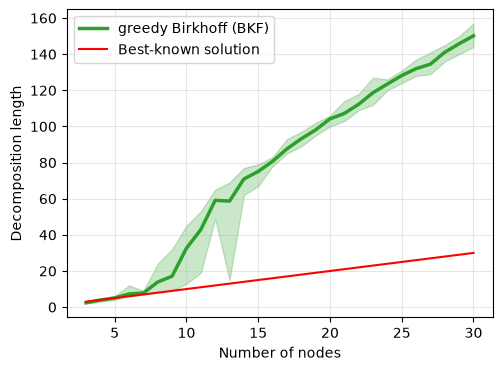

In [4]:
stats = table("fig3_birkhoff").groupby("n")["length"].agg(["min", "max", "mean"])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.fill_between(stats.index, stats["min"], stats["max"], color="#2ca02c", alpha=0.25)
ax.plot(stats.index, stats["mean"], color="#2ca02c", linewidth=2.5, label="greedy Birkhoff (BKF)")
ax.plot(stats.index, stats.index, color="red", label="Best-known solution")
ax.set(xlabel="Number of nodes", ylabel="Decomposition length")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 5.2 First five sampled matchings (Fig. 6 of [1])

Complete graph with $n=8$ (instance 1), first iteration. The top row shows the maximum-weight matching found by
NetworkX [16] (Edmonds' algorithm [5]); the rows below show the five highest-weight *valid* matchings sampled with GW
and SA. In the article, the 2nd–5th matchings sampled with QAOA had lower weight than, and differed from, those of SA.
The MIP row shows the exact five best matchings for comparison.

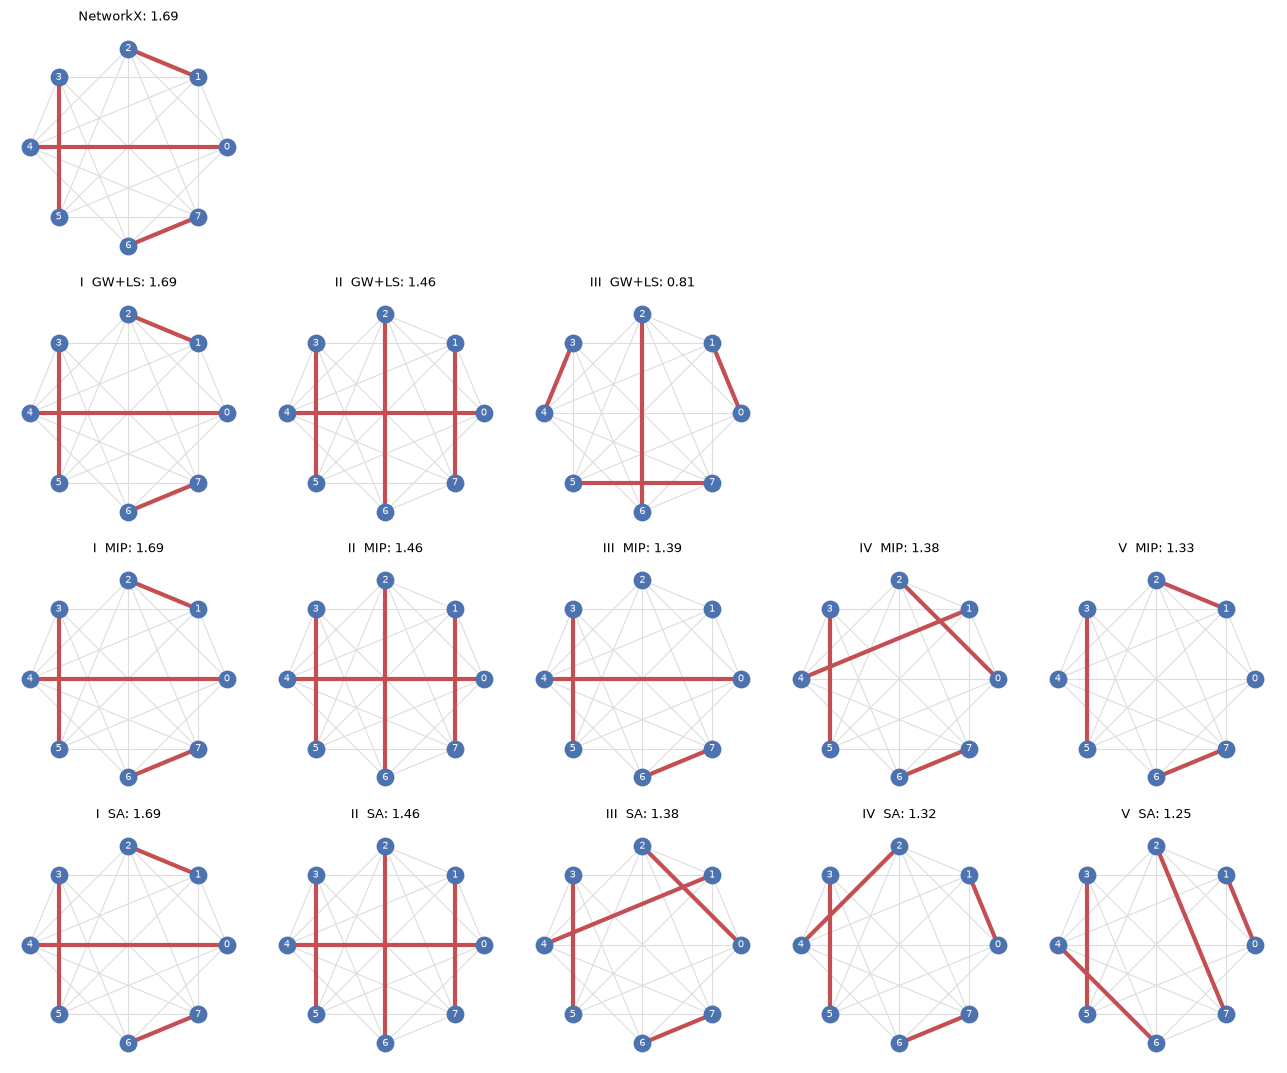

In [5]:
fig6 = DATA["fig6"]
n8, edges8, _ = demand("complete-8-1")
fig, axes = plt.subplots(1 + len(fig6["rows"]), 5, figsize=(13, 2.7 * (1 + len(fig6["rows"]))))
for ax in axes.ravel():
    ax.axis("off")
draw_matching(axes[0, 0], n8, edges8, fig6["mw"], f"NetworkX: {fig6['mw_weight']:.2f}")
for r, (label, matchings) in enumerate(fig6["rows"].items(), start=1):
    for c, (matching, weight) in enumerate(matchings[:5]):
        draw_matching(axes[r, c], n8, edges8, matching, f"{['I', 'II', 'III', 'IV', 'V'][c]}  {label}: {weight:.2f}")
fig.tight_layout()
plt.show()

### 5.3 Complete graphs (Fig. 7 and Table II of [1])

Median decomposition length over 10 instances for $n=6,\dots,9$; the error bars represent the minimum and maximum over
the instances. Lower is better. Averages reported in [1] for $n=9$: FCFW 17.2, random sampling 15.7, QAOA 13.6,
SA 15.1.

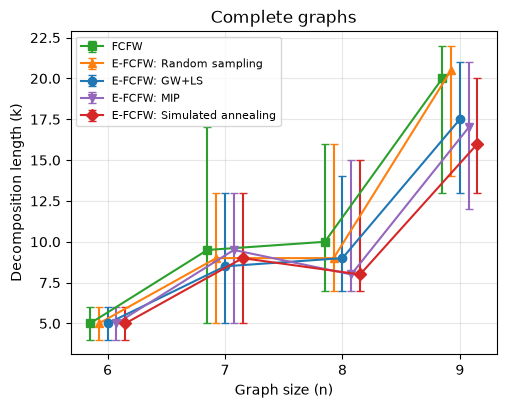

,FCFW,E-FCFW: Random sampling,E-FCFW: GW+LS,E-FCFW: MIP,E-FCFW: Simulated annealing
n,,,,,
6,4.8,4.8,4.8,4.8,4.8
7,9.9,9.3,8.8,9.4,9.2
8,10.4,9.7,9.4,8.9,9.4
9,18.8,19.3,17.5,16.9,16.2


In [6]:
runs_c = runs("complete")
table_c = runs_table(runs_c)
fig7_median_lengths(table_c, "Complete graphs", METHODS_2025)
plt.show()
display(table_c.groupby(["n", "method"]).length.mean().unstack()[METHODS_2025].rename_axis(columns=None)
        .style.format("{:.1f}").set_caption("average decomposition length (Table II, 'Average' rows)"))
per_instance = pd.concat({
    "Decomposition length": table_c.pivot_table(index=["n", "id"], columns="method", values="length")[METHODS_2025],
    "Decomposition approximation": table_c.pivot_table(index=["n", "id"], columns="method", values="cost")[METHODS_2025],
}, axis=1)
display(per_instance.style.format("{:.0f}", subset=pd.IndexSlice[:, "Decomposition length"])
        .format("{:.1e}", subset=pd.IndexSlice[:, "Decomposition approximation"])
        .set_caption("Table II: per-instance lengths and errors"))

**Observation.** As in [1], sampling shortens the decompositions relative to FCFW, but only structured sampling: for
$n=9$, GW+LS, MIP and SA need 16.2–17.5 matchings on average, FCFW 18.8, and uniform random sampling 19.3. The
absolute lengths differ from those of [1] (Sec. 4.3), so the QAOA values of [1] are quoted but not compared directly.

### 5.4 Matching overlap (Fig. 9 of [1])

Complete graph with $n=9$, instance 2. Each cell indicates the number of edges shared by two matchings of the final
decomposition. The article observed lower overlap, i.e., greater diversity, for the shortest decomposition.

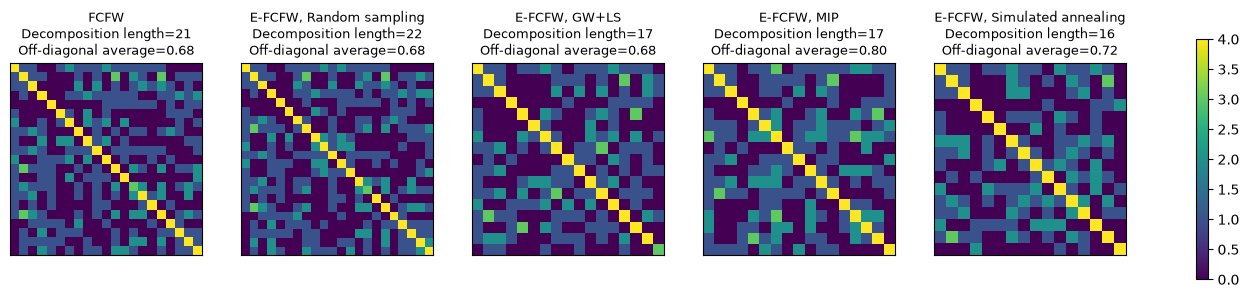

In [7]:
chosen = {r.method.replace("E-FCFW: ", "E-FCFW, "): r for r in runs_c if r.instance == "complete-9-2"}
vmax = max(len(m) for r in chosen.values() for m in r.matchings)
fig, axes = plt.subplots(1, len(chosen), figsize=(3.6 * len(chosen), 3.9))
for ax, (label, r) in zip(axes, chosen.items()):
    overlap = np.array([[len(set(a) & set(b)) for b in r.matchings] for a in r.matchings])  # shared edges
    off_diagonal = overlap[~np.eye(len(overlap), dtype=bool)]
    im = ax.imshow(overlap, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"{label}\nDecomposition length={len(overlap)}\nOff-diagonal average={off_diagonal.mean():.2f}",
                 fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 5.5 Bipartite graphs (Fig. 8 and Table III of [1])

Median decomposition length over 10 instances for $n=6,8,10$, as in Sec. 5.3.

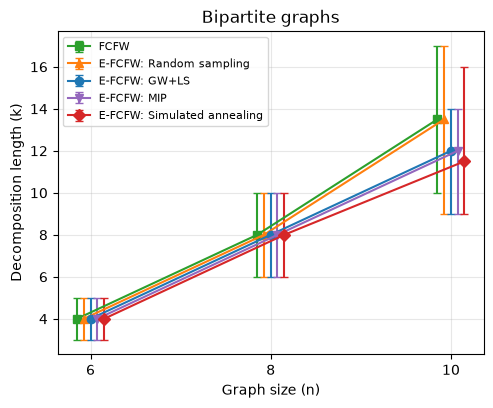

,FCFW,E-FCFW: Random sampling,E-FCFW: GW+LS,E-FCFW: MIP,E-FCFW: Simulated annealing
n,,,,,
6,4.0,4.0,4.0,4.0,4.0
8,7.7,7.8,7.7,7.8,7.6
10,13.5,13.0,11.5,11.7,11.7


In [8]:
table_b = runs_table(runs("bipartite"))
fig7_median_lengths(table_b, "Bipartite graphs", METHODS_2025)
plt.show()
display(table_b.groupby(["n", "method"]).length.mean().unstack()[METHODS_2025].rename_axis(columns=None)
        .style.format("{:.1f}").set_caption("average decomposition length (Table III)"))

**Observation.** For $n=10$, the structured samplers need 11.5–11.7 matchings, FCFW 13.5 and uniform random sampling
13.0; the three structured samplers differ by at most 0.2 matchings.

### 5.6 Heavy-hex graphs (Figs. 10 and 11 of [1])

Decomposition error versus decomposition length on the nine heavy-hex graphs with 50, 70 and 100 nodes and the edge
counts of the article (53/54/52, 76, 110/111/110). In the article, QAOA was executed on IBM Kingston and with MPS
circuit simulation; here GW takes its place. As in the article, none of the uniformly sampled bitstrings correspond to
valid matchings at this scale, so the random-sampling curve coincides with FCFW.

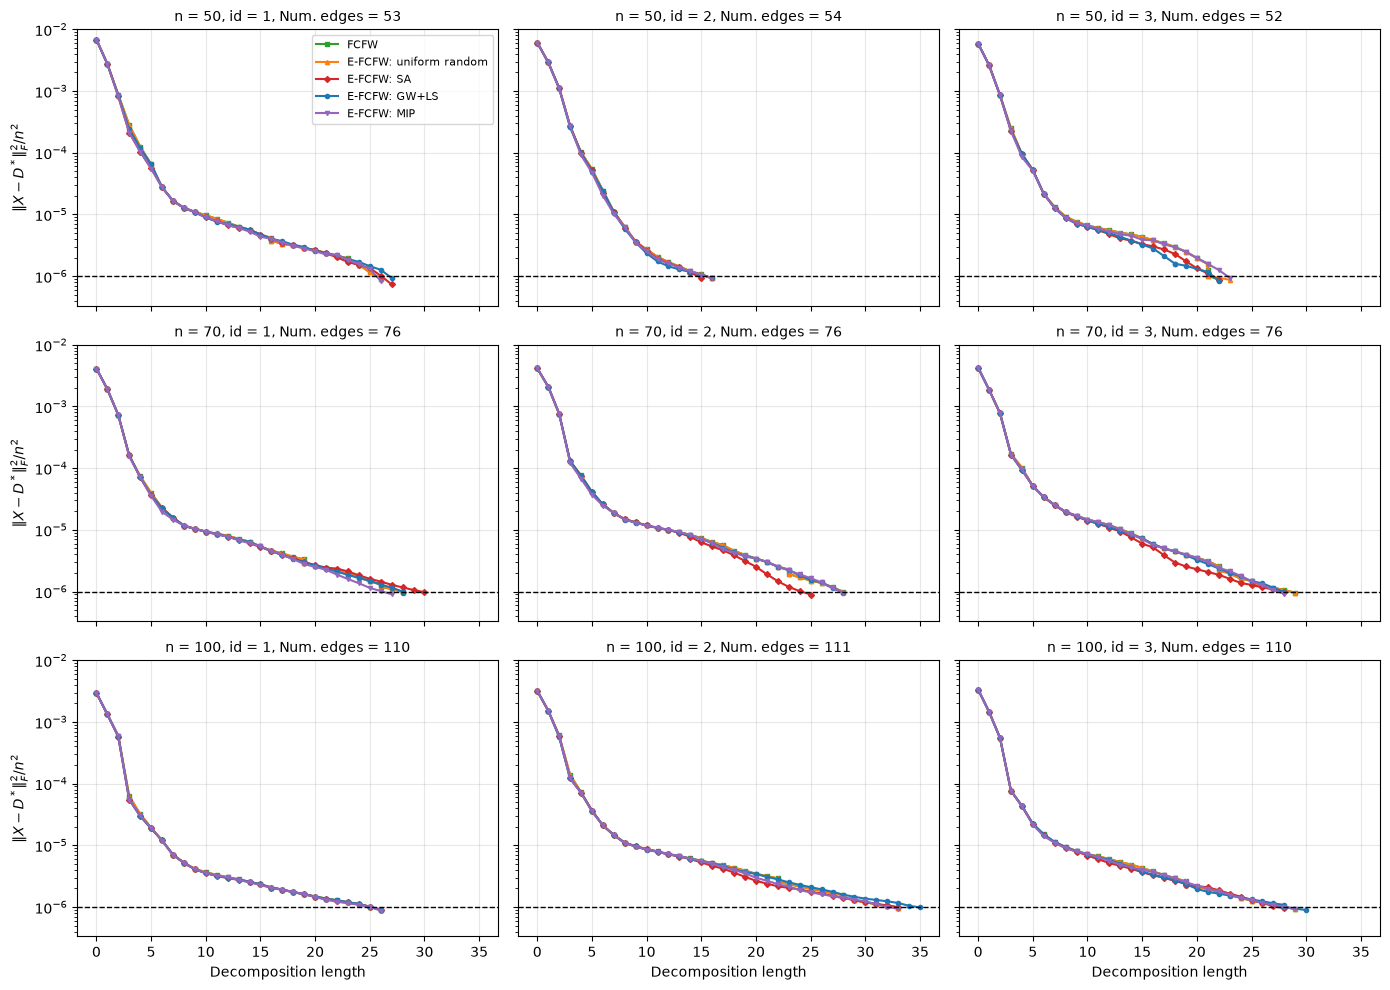

method,FCFW,E-FCFW: uniform random,E-FCFW: SA,E-FCFW: GW+LS,E-FCFW: MIP
instance,,,,,
heavy_hex-50-1,9.07e-07,9.07e-07,7.35e-07,9.35e-07,8.42e-07
heavy_hex-50-2,9.20e-07,9.20e-07,9.45e-07,9.20e-07,9.20e-07
heavy_hex-50-3,8.78e-07,8.73e-07,8.74e-07,8.41e-07,9.43e-07
heavy_hex-70-1,9.93e-07,9.93e-07,9.77e-07,9.35e-07,9.06e-07
heavy_hex-70-2,9.88e-07,9.88e-07,8.97e-07,9.50e-07,9.66e-07
heavy_hex-70-3,9.57e-07,9.57e-07,9.77e-07,9.82e-07,9.18e-07
heavy_hex-100-1,9.12e-07,9.12e-07,8.99e-07,8.87e-07,8.75e-07
heavy_hex-100-2,9.79e-07,9.79e-07,9.98e-07,9.87e-07,9.37e-07
heavy_hex-100-3,9.22e-07,9.22e-07,9.58e-07,8.92e-07,9.44e-07


In [9]:
runs_h = runs("heavyhex")
by_key = {(r.instance, r.method): r for r in runs_h}
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)
for ax, (n, i, num_edges) in zip(axes.ravel(), HEAVY_HEX):
    for method in METHODS_FIG10:
        r = by_key.get((f"heavy_hex-{n}-{i}", method))
        if r is not None:
            color, marker = style(method)
            ax.plot(r.length_history, r.cost_history, marker=marker, markersize=3, color=color, label=method)
    ax.axhline(1e-6, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"n = {n}, id = {i}, Num. edges = {num_edges}", fontsize=10)
    ax.set(yscale="log", ylim=(1e-6 / 3, 1e-2))
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\|X - D^*\|_F^2/n^2$")
for ax in axes[-1]:
    ax.set_xlabel("Decomposition length")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(runs_table(runs_h).pivot_table(index="instance", columns="method", values="cost", sort=False)
        .style.format("{:.2e}").set_caption("final error"))

**Matching weights in the final decomposition** ($n=50$, instance 1; Fig. 11 of [1]). The weight of a matching $M$ is
$\sum_{e\in M} D^*_e$.

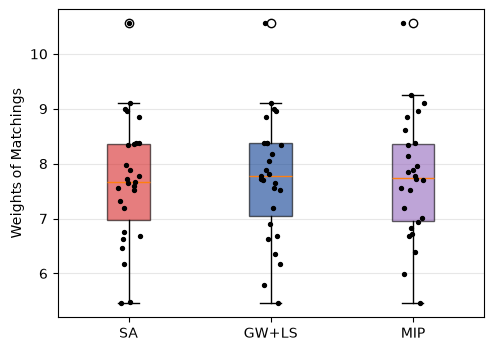

In [10]:
_, _, weights50 = demand("heavy_hex-50-1")
chosen = {r.method.replace("E-FCFW: ", ""): r for r in runs_h
          if r.instance == "heavy_hex-50-1" and r.method in ("E-FCFW: GW+LS", "E-FCFW: MIP", "E-FCFW: SA")}
data = [[weights50[m].sum() for m in r.matchings] for r in chosen.values()]
fig, ax = plt.subplots(figsize=(5.5, 4))
box = ax.boxplot(data, patch_artist=True)
for patch, label in zip(box["boxes"], chosen):
    patch.set_facecolor(style(label)[0] or "#cccccc")
    patch.set_alpha(0.6)
for k, values in enumerate(data, start=1):
    jitter = np.random.default_rng(k).uniform(-0.08, 0.08, len(values))
    ax.scatter(k + jitter, values, color="black", s=8, zorder=3)
ax.set_xticks(range(1, len(chosen) + 1), list(chosen))
ax.set_ylabel("Weights of Matchings")
ax.grid(axis="y", alpha=0.3)
plt.show()

**Observation.** On these sparse graphs, all methods end within 3% of each other (geometric mean of the final error
$9.1\text{–}9.4\times10^{-7}$, 26–27 matchings): sampling hardly improves on FCFW here.

### 5.7 Choice of the classical sampler

I run the same E-FCFW pipeline (2025 setting) on the 30 original instances on which the methods differ most
(complete graphs with $n=8,9$, bipartite graphs with $n=10$), with different QUBO solvers in the sampling subroutine.
The table reports the mean decomposition length (lower is better) and the mean time spent in the sampler per run.

In [11]:
display(table("qubo_solvers", header=[0, 1], index_col=0).round(2))

kind                               complete       bipartite  \
n                                         8     9        10   
solver                                                        
FCFW                                   10.4  18.8      13.5   
Random (10,000)                         9.7  19.3      13.0   
SA (1,000 reads)                        9.4  16.2      11.7   
GW (50)                                 9.4  18.7      12.5   
GW (10,000)                             9.2  17.3      11.9   
GW + local search (50)                  9.2  17.3      11.6   
GW + local search (1,000)               9.4  17.5      11.5   
MIP: 10 best matchings                  8.9  16.9      11.7   
Random (10,000) + Boltzmann filter      9.7  19.6      12.2   

kind                                      mean length mean sampler time [s]  
n                                  Unnamed: 4_level_1    Unnamed: 5_level_1  
solver                                                                       
FCFW                                            14.23                  0.00  
Random (10,000)                                 14.00                  0.26  
SA (1,000 reads)                                12.43                  8.11  
GW (50)                                         13.53                  0.20  
GW (10,000)                                     12.80                  0.40  
GW + local search (50)                          12.70                  0.17  
GW + local search (1,000)                       12.80                  0.19  
MIP: 10 best matchings                          12.50                  1.24  
Random (10,000) + Boltzmann filter              13.83                  0.10

**Observation.** Plain GW with 50 hyperplanes improves only slightly on uniform random sampling (13.5 versus 14.0
matchings); more hyperplanes or a one-flip local search close the gap to SA (12.7–12.8 versus 12.4) at a small
fraction of its sampling time (0.2 s versus 8.1 s per run). The exact 10 best matchings (MIP, 12.5) are no better
than SA. GW+LS with 1,000 hyperplanes is therefore used in the place of QAOA throughout. The last row is the
Boltzmann-filtered random sampler of Sec. 7.4.

## 6. Experiments of the 2026 article [2]

All runs in this section use the 2026 setting of Sec. 4.2.

### 6.1 Synthetic Heron-topology graph with 120 nodes and 132 edges (Fig. 2(a) of [2])

The article curves "QAOA Sim" and "QAOA Sim ($p_s$=50)" are replaced by "GW+LS" and "GW+LS ($p_s$=50)", and MIP is
added. The partitioned run omits $M^{MW}$ (Sec. 1.3). The hardware curves and Fig. 2(b) (MPS bond dimension) concern
quantum execution and are omitted.

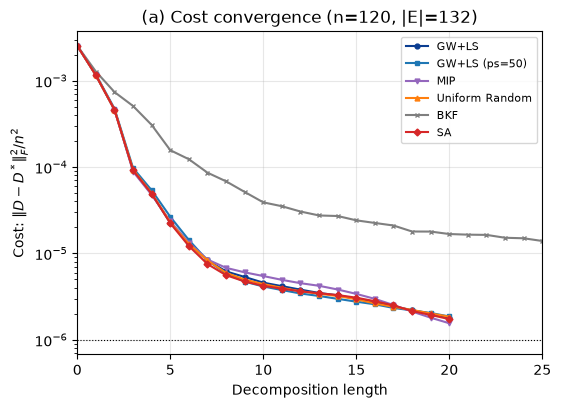

,decomposition length,final cost,runtime [s],stop
method,,,,
GW+LS,20,1.803e-06,219.320,max iterations
GW+LS (ps=50),20,1.862e-06,6.584,max iterations
MIP,20,1.555e-06,2.913,max iterations
Uniform Random,20,1.852e-06,6.135,max iterations
BKF,25,1.394e-05,0.012,max length
SA,20,1.736e-06,64.219,max iterations


In [12]:
runs_2a = runs("fig2a")
fig_convergence(runs_2a, FIG2A, "(a) Cost convergence (n=120, |E|=132)")
plt.show()
display(pd.DataFrame([{"method": r.method, "decomposition length": r.decomposition_length, "final cost": r.cost,
                       "runtime [s]": r.runtime_s, "stop": r.stop_reason} for r in runs_2a]).set_index("method"))

**Observation.** All E-FCFW variants end at errors of $1.6\text{–}1.9\times10^{-6}$ after 20 iterations, about eight
times below BKF; partitioned GW+LS ends 3% above unpartitioned GW+LS.

### 6.2 PEGASE-1354 (Figs. 3(a) and 3(c) of [2])

(a) Partition bounds $p_s\in\{20,50,80\}$ for GW+LS, compared with SA ($p_s$=50, 80), MIP, uniform random sampling
and Boltzmann-filtered random sampling (Sec. 7.4) ($p_s$=50), all with feasibility repair. (c) GW+LS with and without
greedy repair; without repair, invalid candidates are discarded. Panel (b) of the article (hardware versus
simulation, spatial circuit packing) concerns quantum execution and is omitted. Since every repaired run reaches the
target error early, panel (a') repeats (a) without the tolerance criterion, i.e., for all 20 iterations (Sec. 3).

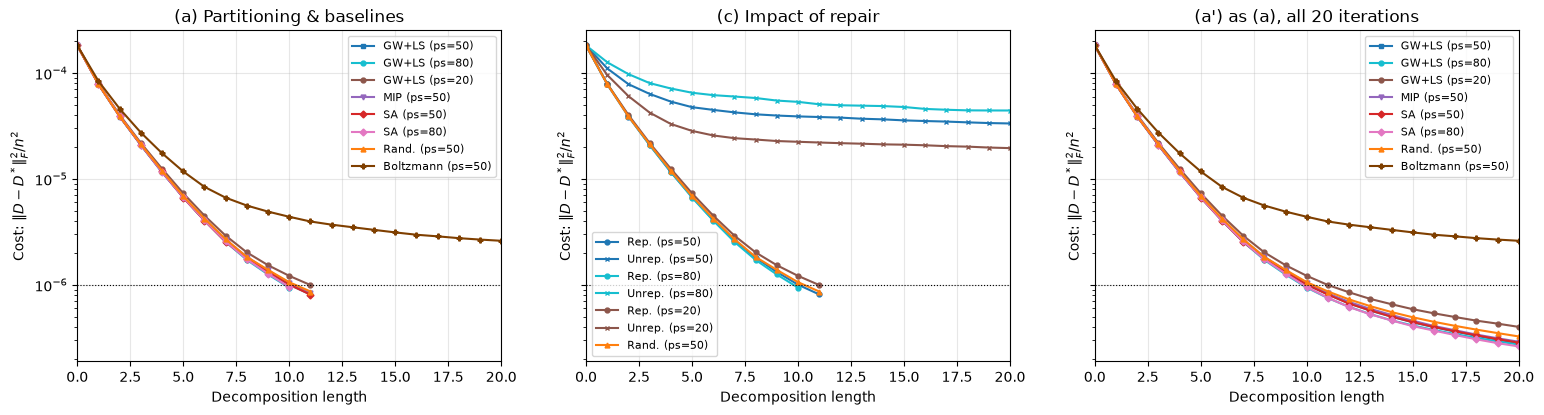

decomposition length  final cost  runtime [s]  \
panel      method                                                             
fig3a      GW+LS (ps=50)                        11   8.108e-07      107.496   
           GW+LS (ps=80)                        10   9.400e-07      283.940   
           GW+LS (ps=20)                        11   9.944e-07       28.477   
           MIP (ps=50)                          11   8.292e-07       68.654   
           SA (ps=50)                           11   8.071e-07      500.038   
           SA (ps=80)                           10   9.510e-07      483.473   
           Rand. (ps=50)                        11   8.640e-07       72.315   
           Boltzmann (ps=50)                    20   2.604e-06       54.520   
fig3c      Rep. (ps=50)                         11   8.108e-07       86.679   
           Unrep. (ps=50)                       20   3.344e-05      162.953   
           Rep. (ps=80)                         10   9.400e-07      224.495   
           Unrep. (ps=80)                       20   4.432e-05      494.379   
           Rep. (ps=20)                         11   9.944e-07       27.337   
           Unrep. (ps=20)                       20   1.956e-05       70.826   
           Rand. (ps=50)                        11   8.640e-07       74.460   
fig3a_full GW+LS (ps=50)                        20   2.808e-07      184.813   
           GW+LS (ps=80)                        20   2.721e-07      502.336   
           GW+LS (ps=20)                        20   4.002e-07       68.579   
           MIP (ps=50)                          20   2.896e-07      128.779   
           SA (ps=50)                           20   2.843e-07      912.693   
           SA (ps=80)                           20   2.615e-07      958.276   
           Rand. (ps=50)                        20   3.250e-07      144.829   
           Boltzmann (ps=50)                    20   2.604e-06       55.061   

                                        stop  
panel      method                             
fig3a      GW+LS (ps=50)           tolerance  
           GW+LS (ps=80)           tolerance  
           GW+LS (ps=20)           tolerance  
           MIP (ps=50)             tolerance  
           SA (ps=50)              tolerance  
           SA (ps=80)              tolerance  
           Rand. (ps=50)           tolerance  
           Boltzmann (ps=50)  max iterations  
fig3c      Rep. (ps=50)            tolerance  
           Unrep. (ps=50)     max iterations  
           Rep. (ps=80)            tolerance  
           Unrep. (ps=80)            plateau  
           Rep. (ps=20)            tolerance  
           Unrep. (ps=20)     max iterations  
           Rand. (ps=50)           tolerance  
fig3a_full GW+LS (ps=50)      max iterations  
           GW+LS (ps=80)      max iterations  
           GW+LS (ps=20)      max iterations  
           MIP (ps=50)        max iterations  
           SA (ps=50)         max iterations  
           SA (ps=80)         max iterations  
           Rand. (ps=50)      max iterations  
           Boltzmann (ps=50)  max iterations

In [13]:
panels = [("fig3a", FIG3A, "(a) Partitioning & baselines"), ("fig3c", FIG3C, "(c) Impact of repair"),
          ("fig3a_full", FIG3A, "(a') as (a), all 20 iterations")]
fig, axes = plt.subplots(1, 3, figsize=(18.6, 4.3), sharey=True)
rows = []
for ax, (key, methods, title) in zip(axes, panels):
    rs = runs(key)
    fig_convergence(rs, methods, title, ax=ax, max_length=20)
    rows += [{"panel": key, "method": r.method, "decomposition length": r.decomposition_length, "final cost": r.cost,
              "runtime [s]": r.runtime_s, "stop": r.stop_reason} for r in rs]
plt.show()
display(pd.DataFrame(rows).set_index(["panel", "method"]))

**Observation.** With $M^{MW}$ omitted, every matching of the decomposition comes from the partitioned samples.

* **Repair decides convergence.** With repair, every run reaches $\varepsilon=10^{-6}$ with 10 or 11 matchings; without
  repair, convergence stalls at errors between $2\times10^{-5}$ and $4\times10^{-5}$, in line with the observation of
  [2] that discarding invalid matchings stalls convergence above $10^{-5}$.
* **Partition size matters next.** After 20 iterations, small partitions ($p_s=20$) end 42% above $p_s=50$
  ($4.0$ versus $2.8\times10^{-7}$).
* **The structured samplers are close.** At $p_s=50$, GW+LS, SA and MIP end within 3% of each other
  ($2.8\text{–}2.9\times10^{-7}$), uniform random sampling 15% higher ($3.3\times10^{-7}$), and the
  Boltzmann-filtered sampler does not reach the target at all.

### 6.3 PEGASE-1354 partitioned with $p_s=50$ (Fig. 4 of [2])

The article reports 41 subgraphs. Colors distinguish neighboring partitions, and dashed red lines are cut edges.

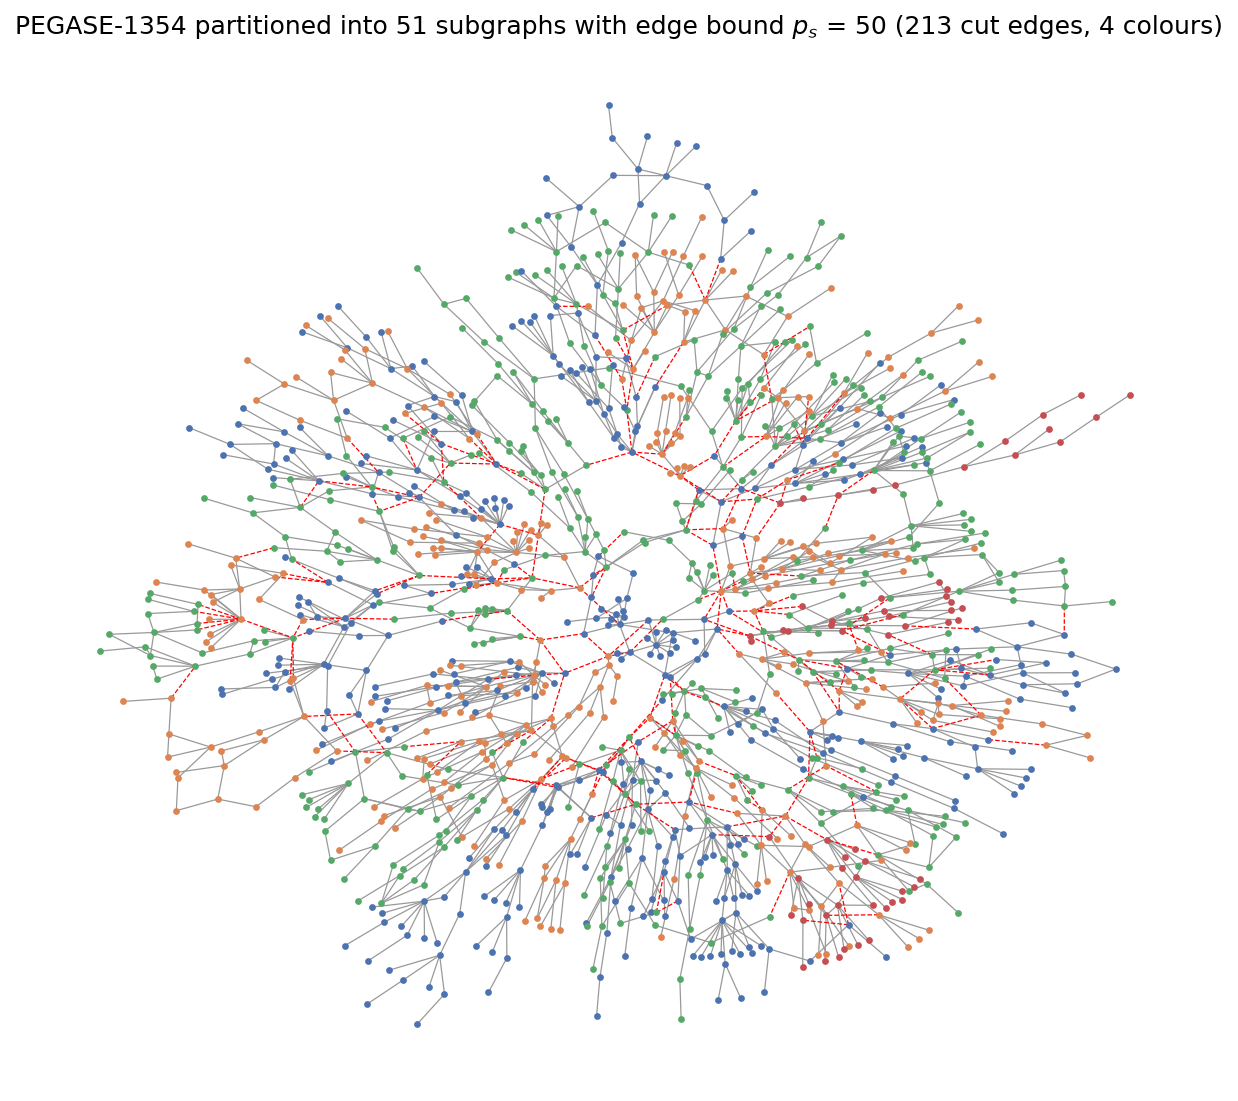

In [14]:
image("fig4_pegase_partitions", width=800)

## 7. What determines the quality of the decomposition

### 7.1 Benchmark

To compare the samplers on instances on which none of them is trivially sufficient, I run the 2026 pipeline on 18
graphs: heavy-hex graphs and connected subgraphs of PEGASE-1354 with 40, 60 and 80 nodes, three of each, all limited
to 20 iterations and 60 seconds per run. The samplers run partitioned ($p_s=50$) without $M^{MW}$; FCFW, which applies
the global maximum-weight matching to the unpartitioned residual graph, and BKF serve as references. Following common
practice in optimization benchmarking [18], the results are summarized by the shifted geometric mean

$$ \operatorname{SGM}_s(f_1,\dots,f_N)=\exp\Big(\tfrac1N\sum_{i=1}^N \ln(f_i+s)\Big)-s , $$

with $s=10^{-7}$ for the normalized error $f$ (final, and the best error with at most $L$ matchings) and $s=1$ s for
the runtime.

,instances,SGM objective (final),relative to best,SGM objective @ length 10,SGM objective @ length 20,SGM runtime [s],timeouts
method,,,,,,,
GW+LS,18,3.44e-06,1.09,1.59e-05,3.44e-06,3.73,0
MIP,18,3.58e-06,1.14,1.76e-05,3.58e-06,3.82,0
SA,18,3.31e-06,1.05,1.76e-05,3.31e-06,33.9,0
Random,18,5.09e-06,1.62,2.20e-05,5.09e-06,4.31,0
Boltzmann,18,3.48e-05,11.07,6.17e-05,3.48e-05,2.25,0
BKF,18,1.44e-05,4.57,1.06e-04,1.44e-05,0.00314,0
FCFW,18,3.14e-06,1.00,1.37e-05,3.14e-06,0.00571,0


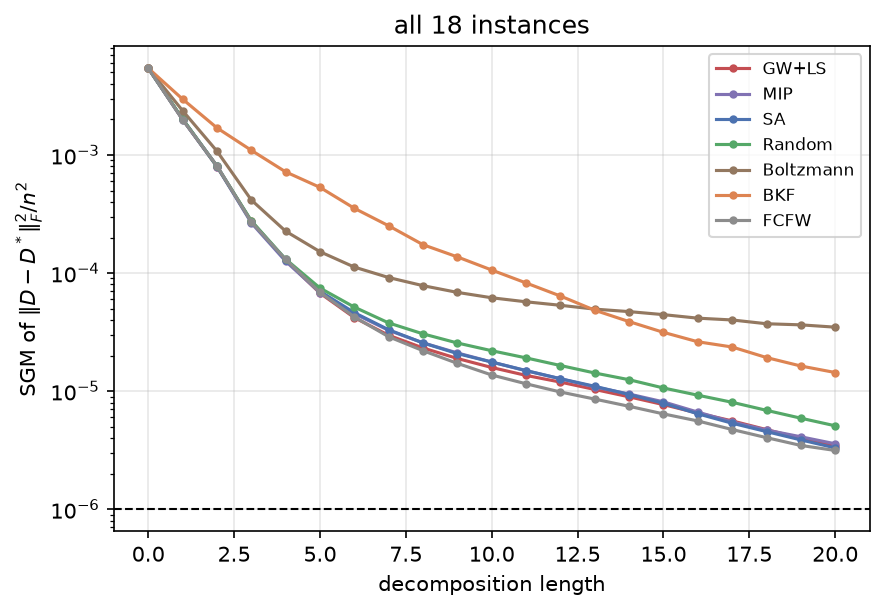

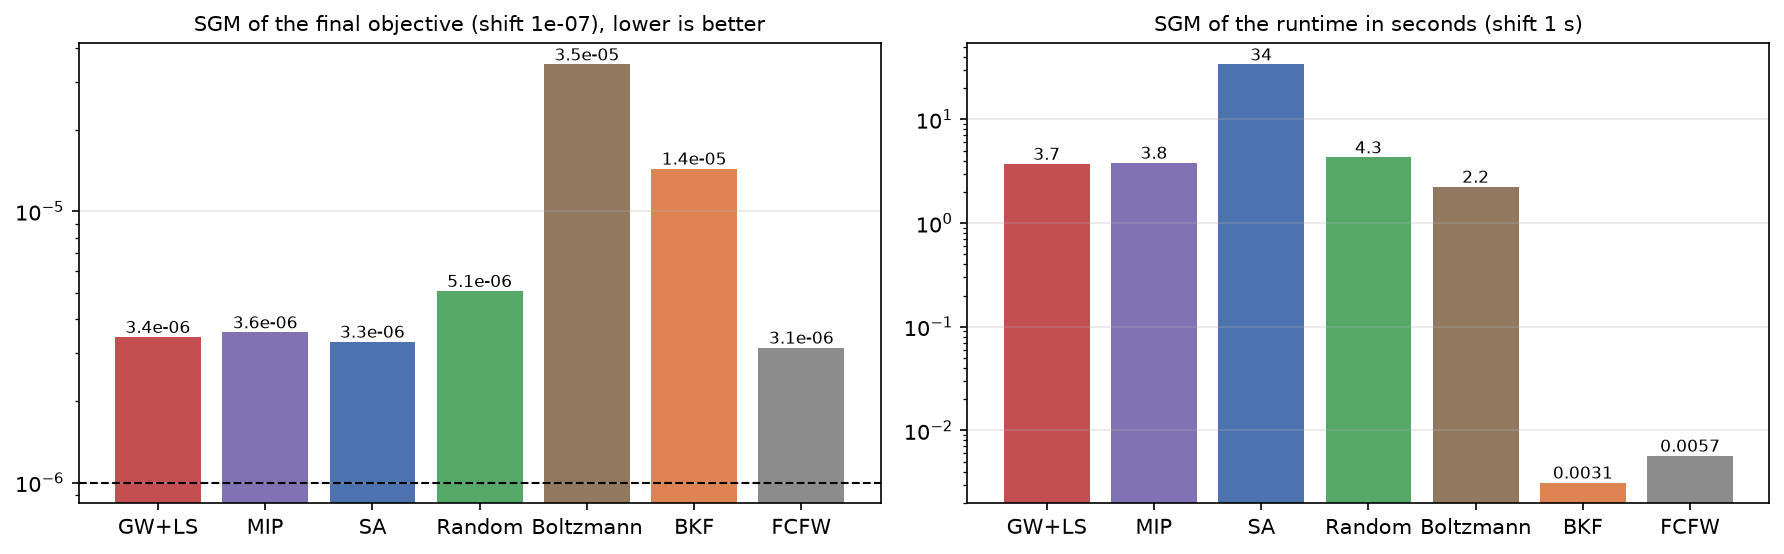

In [15]:
summary = table("benchmark_summary", index_col=0)
display(summary[["instances", "SGM objective (final)", "relative to best", "SGM objective @ length 10",
                 "SGM objective @ length 20", "SGM runtime [s]", "timeouts"]]
        .style.format({"SGM objective (final)": "{:.2e}", "relative to best": "{:.2f}",
                       "SGM objective @ length 10": "{:.2e}", "SGM objective @ length 20": "{:.2e}",
                       "SGM runtime [s]": "{:.3g}"}))
image("benchmark_sgm_convergence", width=760)
image("benchmark_sgm_bars", width=760)

**Observation.** In this single run (seed 0), FCFW attains the lowest error, followed by SA, GW+LS and MIP within 8%
of each other; uniform random sampling is 54% above SA, and the Boltzmann-filtered sampler is far behind. SA is by far
the most expensive sampler: over the 18 graphs, it needs about nine times the runtime of GW+LS (641 s versus 74 s in
total). The decomposition itself is cheap: FCFW and BKF finish in milliseconds, so almost all of the runtime is spent
in the sampler. Whether the
small differences between the structured samplers are systematic is examined next.

### 7.2 Variation between random seeds

Each seed changes the samples and the restarts of $k$-means++ in the partitioning; the resulting partitions turn out
to be the same, so MIP, which is deterministic for a given partition, gives identical results in all seeds. For GW+LS
and SA, the error of a single run on one instance changes between seeds by a median factor of 1.1–1.2 and by up to a
factor of 4–6, which is larger than the differences between the samplers. I therefore repeat the whole benchmark with 10 seeds, for GW+LS, SA, MIP and uniform random sampling, each with greedy
repair and with cut-edge filling (Sec. 7.3). FCFW is deterministic and serves as
the reference. To run the 80 repetitions quickly, they were computed with a compiled port of the same pipeline, whose
results agree with this implementation within the variation between seeds.

SGM of the final error over the 18 graphs, per seed: mean, minimum and maximum over 10 seeds


Greedy repair: share of the 10 seeds in which the row sampler has a lower SGM than the column sampler


,GW+LS,SA,MIP,Random
GW+LS,–,0.2,0.5,1.0
SA,0.8,–,0.9,1.0
MIP,0.5,0.1,–,1.0
Random,0.0,0.0,0.0,–


,best on an instance (share),fill better than greedy (share of seeds)
GW+LS,0.34,1.00
SA,0.28,1.00
MIP,0.26,1.00
Random,0.12,0.80


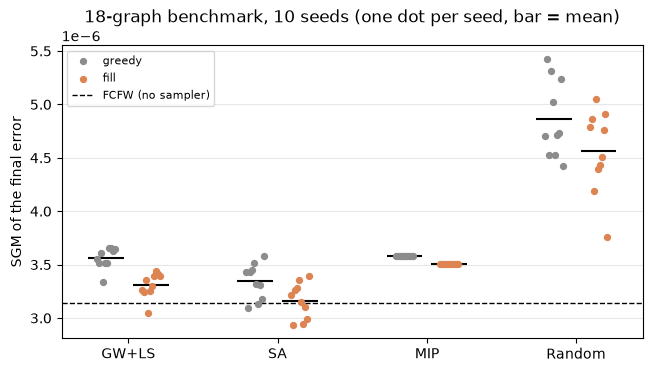

In [16]:
seeds = table("seeds_summary", index_col=[0, 1]).rename_axis(["repair", "sampler"])
print("SGM of the final error over the 18 graphs, per seed: mean, minimum and maximum over 10 seeds")
display(seeds.style.format({"mean": "{:.2e}", "min": "{:.2e}", "max": "{:.2e}", "max/min": "{:.2f}",
                            "relative to FCFW": "{:.2f}"}))
print("Greedy repair: share of the 10 seeds in which the row sampler has a lower SGM than the column sampler")
display(table("seeds_paired", index_col=0).style.format("{:.1f}", na_rep="–"))
display(table("seeds_wins", index_col=0).style.format("{:.2f}"))

per_seed = table("seeds_per_seed")
fcfw = per_seed.loc[per_seed.method == "FCFW", "sgm"].item()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, method in enumerate(["GW+LS", "SA", "MIP", "Random"]):
    for j, (variant, color) in enumerate([("greedy", "#8c8c8c"), ("fill", "#dd8452")]):
        values = per_seed[(per_seed.method == method) & (per_seed.variant == variant)].sgm.to_numpy()
        x = i + (j - 0.5) * 0.3
        ax.scatter(x + np.linspace(-0.06, 0.06, len(values)), values, s=18, color=color, zorder=3,
                   label=variant if i == 0 else None)
        ax.hlines(values.mean(), x - 0.12, x + 0.12, color="black", lw=1.5)
ax.axhline(fcfw, color="black", ls="--", lw=1, label="FCFW (no sampler)")
ax.set_xticks(range(4), ["GW+LS", "SA", "MIP", "Random"])
ax.set(ylabel="SGM of the final error", title="18-graph benchmark, 10 seeds (one dot per seed, bar = mean)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8)
plt.show()

**Results.**

* **Structured versus uniform samples.** Uniform random sampling is worse than every structured sampler in all 10
  seeds, by 36–46% on average.
* **Among the structured samplers, differences are small.** The mean errors of SA, GW+LS and MIP lie within 7% of
  each other. SA has a small but consistent advantage: its SGM is lower than that of GW+LS in 8 of 10 seeds and lower
  than that of MIP in 9 of 10. On individual instances, however, the best sampler varies: GW+LS is best on 34% of the
  (instance, seed) pairs, SA on 28% and MIP on 26%.
* **A perfect QUBO optimizer is not better.** MIP, which returns the exact 10 best solutions of every QUBO, is on par
  with GW+LS and behind SA. Its 10 best matchings are close variants of one another, so its candidates are heavier but
  less diverse than those of SA. For E-FCFW, a set of different good matchings is worth more than the
  best matchings of each subgraph.
* **No sampler beats FCFW.** With greedy repair, the partitioned samplers end 6% (SA) to 14% (MIP) above the
  unpartitioned FCFW, which uses the global maximum-weight matching alone.
* **The cut edges matter as much as the sampler.** Filling the cut edges lowers the error of GW+LS, SA and MIP in
  every seed (by 7%, 5% and 2% on average), i.e., by about as much as the spread between them; with filling, SA
  reaches FCFW (ratio 1.01) and GW+LS comes within 5%. For uniform random sampling, filling helps in 8 of 10 seeds
  (6% on average).

### 7.3 Variants of the repair step

Greedy repair (Appendix A.2 of [2]) turns a sample into a matching by keeping its selected edges in order of
decreasing weight, as long as both endpoints are free. I test two modifications, which leave the samplers, the
partitioning and the selection of the five heaviest candidates unchanged:

* **Optimal repair.** Each sample is replaced by the maximum-weight matching among its selected edges, computed with
  Edmonds' algorithm [5]. To keep the cost low, it is computed only for samples whose upper bound
  $\tfrac12\sum_{v}\max_{e\ni v} w_e$ (over the selected edges) can reach the five heaviest greedy-repaired samples;
  all other samples keep greedy repair.
* **Cut-edge filling.** After stitching, a maximum-weight matching on the cut edges between the nodes that a candidate
  leaves free is added to it. The cut edges are seen by no sampler, so without this step they enter a matching only
  through $M^{MW}$, which is disabled in the partitioned regime.
* **Both** modifications together.

The benchmark of Sec. 7.1 and the PEGASE-1354 runs of Fig. 3(a') (20 iterations, $\varepsilon=0$) are repeated with
each variant (seed 0, Python); the greedy results are those of Secs. 6.2 and 7.1.

Benchmark (18 graphs): SGM of the final error


variant,greedy,optimal,fill,both,FCFW (reference)
method,,,,,
GW+LS,3.44e-06,3.44e-06,3.20e-06,3.20e-06,3.14e-06
SA,3.31e-06,3.31e-06,3.10e-06,3.10e-06,3.14e-06
MIP,3.58e-06,3.58e-06,3.50e-06,3.50e-06,3.14e-06
Random,5.09e-06,4.72e-06,4.56e-06,4.44e-06,3.14e-06


PEGASE-1354: error after 20 iterations


variant,greedy,optimal,fill,both
run,,,,
GW+LS (ps=50),2.81e-07,2.81e-07,2.34e-07,2.34e-07
GW+LS (ps=20),4.00e-07,4.00e-07,2.57e-07,2.57e-07
SA (ps=50),2.84e-07,2.84e-07,2.35e-07,2.35e-07
Rand. (ps=50),3.25e-07,3.03e-07,2.78e-07,2.47e-07


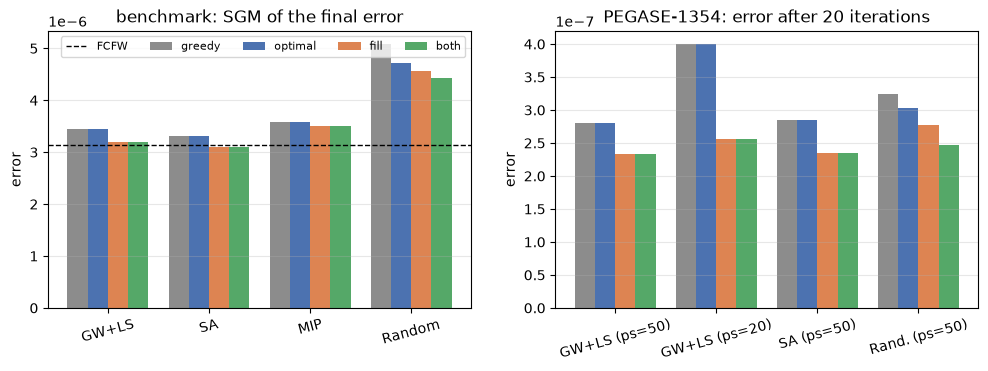

In [17]:
VARIANT_ORDER = ["greedy", "optimal", "fill", "both"]
rv = table("repair_benchmark")
repair = rv.pivot(index="method", columns="variant", values="sgm_final").loc[["GW+LS", "SA", "MIP", "Random"],
                                                                              VARIANT_ORDER]
repair["FCFW (reference)"] = summary.loc["FCFW", "SGM objective (final)"]
print("Benchmark (18 graphs): SGM of the final error")
display(repair.style.format("{:.2e}"))
peg = table("repair_pegase").pivot(index="run", columns="variant", values="cost@20")
peg = peg.loc[["GW+LS (ps=50)", "GW+LS (ps=20)", "SA (ps=50)", "Rand. (ps=50)"], VARIANT_ORDER]
print("PEGASE-1354: error after 20 iterations")
display(peg.style.format("{:.2e}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
colors = dict(zip(VARIANT_ORDER, ["#8c8c8c", "#4c72b0", "#dd8452", "#55a868"]))
for ax, data, title in ((axes[0], repair[VARIANT_ORDER], "benchmark: SGM of the final error"),
                        (axes[1], peg, "PEGASE-1354: error after 20 iterations")):
    x = np.arange(len(data))
    for i, variant in enumerate(VARIANT_ORDER):
        ax.bar(x + (i - 1.5) * 0.2, data[variant], 0.2, label=variant, color=colors[variant])
    ax.set_xticks(x, data.index, rotation=15)
    ax.set(title=title, ylabel="error")
    ax.grid(axis="y", alpha=0.3)
axes[0].axhline(repair["FCFW (reference)"].iloc[0], color="black", ls="--", lw=1, label="FCFW")
axes[0].legend(fontsize=8, ncol=5)
plt.show()

**Results.**

* **Optimal repair** changes nothing for GW+LS, SA and MIP: their best samples are already matchings, or greedy repair
  is optimal for them. Only for uniform random samples does it help (shifted geometric mean of the error
  $4.7\times10^{-6}$ instead of $5.1\times10^{-6}$ on the benchmark), at the price of a much higher runtime on
  PEGASE-1354 (about 1,600 s instead of 145 s), since many random samples pass the bound.
* **Cut-edge filling** improves every structured sampler, on the benchmark by 2% (MIP) to 7% (GW+LS), consistent with
  the 10-seed study of Sec. 7.2. On PEGASE-1354, which has many more cut edges, the error after 20 iterations drops by
  17% for GW+LS and SA ($p_s=50$), and by 36% for GW+LS with small partitions ($p_s=20$, $2.6\times10^{-7}$), which
  is then better than $p_s=50$ with greedy repair ($2.8\times10^{-7}$).
* **Both** together give uniform random sampling on PEGASE-1354 an error ($2.5\times10^{-7}$) lower than that of
  any sampler with greedy repair ($2.8\times10^{-7}$ for GW+LS).

The loss due to partitioning lies mainly in the cut edges: a simple classical post-processing step on them improves
the decomposition more than replacing one structured sampler by another.

### 7.4 Boltzmann-filtered random sampling

The output of a quantum annealer is often modeled by a Boltzmann distribution: a high peak at the lowest costs and an
exponential decay towards higher costs. To test whether this shape alone helps the decomposition, I construct such a
sampler classically from uniform random sampling. The same number of uniform random bitstrings as for uniform random
sampling is drawn (10,000 in the 2025 setting, 25,000 in the 2026 setting), and each bitstring $x$ is kept with
probability

$$ p(x) = \exp\big(-\beta\,(C(x)-C_{\min})\big), $$

where $C_{\min}$ is the lowest QUBO cost among the drawn bitstrings. This rejection sampling leaves samples distributed
as $\exp(-\beta\,C(x))$ times the cost distribution of the uniform draw. The inverse temperature $\beta$ is chosen per
QUBO as the smallest value for which this distribution peaks at the best costs: the drawn costs are divided into 40
equal-width bins, and the lowest bin must carry the largest expected weight $\sum\exp(-\beta\,(C-C_{\min}))$. Since a
larger $\beta$ shifts weight towards lower costs, the condition is monotone in $\beta$, and $\beta$ is found by
bisection. The resulting distribution peaks at the best costs and decays from there; in return, only a small fraction
of the draws is kept (typically 10–20 bitstrings per QUBO). The figure shows the QUBO costs of the uniform and of the
Boltzmann-filtered samples for a PEGASE subgraph with 60 nodes.

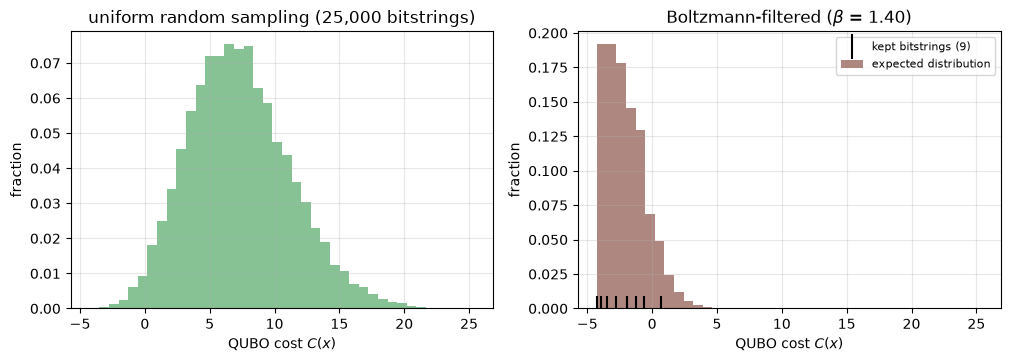

In [18]:
b = DATA["boltzmann"]
C, beta, kept = np.array(b["uniform_costs"]), b["beta"], np.array(b["kept_costs"])   # QUBO costs of the samples
edges = np.linspace(C.min(), C.max(), 41)                                               # the 40 bins of the criterion
counts, _ = np.histogram(C, bins=edges)
expected, _ = np.histogram(C, bins=edges, weights=np.exp(-beta * (C - C.min())))
centers, width = 0.5 * (edges[1:] + edges[:-1]), edges[1] - edges[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(centers, counts / counts.sum(), width=width, color="#55a868", alpha=0.7)
axes[0].set(title=f"uniform random sampling ({len(C):,} bitstrings)", xlabel="QUBO cost $C(x)$", ylabel="fraction")
axes[1].bar(centers, expected / expected.sum(), width=width, color="#8c564b", alpha=0.7, label="expected distribution")
axes[1].plot(kept, np.zeros(len(kept)), "|", color="black", ms=18, mew=1.5, label=f"kept bitstrings ({len(kept)})")
axes[1].set(title=f"Boltzmann-filtered ($\\beta$ = {beta:.2f})", xlabel="QUBO cost $C(x)$", ylabel="fraction",
            xlim=axes[0].get_xlim())
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.show()

**Results.**

* **Without repair** (2025 setting, Sec. 5.7), the filter is marginally better than uniform random sampling (mean
  decomposition length 13.8 versus 14.0), and the structured samplers remain clearly ahead (12.4–12.8).
* **With repair** (2026 setting), it is markedly worse: on PEGASE-1354 ($p_s=50$) it does not reach
  $\varepsilon=10^{-6}$ within 20 iterations (error $2.6\times10^{-6}$, versus $3.3\times10^{-7}$ for uniform random
  sampling and $2.8\times10^{-7}$ for GW+LS), and on the benchmark the shifted geometric mean of the final error is
  $3.5\times10^{-5}$, about seven times that of uniform random sampling and higher than that of BKF.

Under the mild penalty $\lambda=0.2$, the QUBO cost of a raw bitstring is a poor predictor of the weight of its
repaired matching. The filter discards more than 99.9% of the draws, among them most of the bitstrings that greedy
repair would turn into good candidates, and keeps about a dozen low-cost bitstrings per subgraph with little variety.
Concentrating the samples at low QUBO cost is therefore not beneficial in this pipeline; what matters is the quality
and the diversity of the repaired candidates, the same conclusion as for MIP in Sec. 7.2.

## 8. Conclusions

I re-ran every non-quantum experiment of [1] and [2] with classical samplers in the place of QAOA, and extended the
2026 study by a benchmark over 18 graphs, 10 random seeds, variants of the repair step and a Boltzmann-shaped
sampler. With the correction of Algorithm 1 by the authors of [2], the qualitative observations of [2]
are reproduced. The conclusions are:

1. **The decomposition quality is determined by the classical parts of the pipeline.** Feasibility repair decides
   whether the partitioned decomposition converges at all (errors of $2\text{–}4\times10^{-5}$ without repair, target
   reached with 10–11 matchings with repair), the partition size changes the error by about 40%, and the treatment
   of the cut edges by 2–36%.
2. **The sampler has to supply structured samples, and nothing more is gained by optimizing harder.** Uniform random
   samples are 36–46% worse; GW+LS, SA and the exact 10 best QUBO solutions (MIP) lie within 7% of each other. The
   exact solutions are not better than heuristic samples, and concentrating samples at low QUBO cost (Boltzmann
   filtering) is harmful. A better QUBO optimizer therefore does not translate into a better decomposition; the
   diversity of the repaired candidates matters more than their QUBO cost.
3. **The remaining differences between samplers are as large as the gain of a simple classical step.** SA has a small
   but consistent advantage of about 6% over GW+LS; filling the cut edges improves every structured sampler in every
   seed, by 2–7%, and brings SA to the level of the unpartitioned FCFW. Without it, no partitioned sampler beats FCFW on the
   benchmark.
4. **A classical sampler is sufficient and inexpensive.** GW+LS comes within about 6% of the error of SA at about
   a ninth of its runtime.

For the sampling subroutine, a quantum sampler would therefore have to improve the decomposition through more diverse
candidates rather than lower QUBO costs, and it would have to outperform classical samplers that already come within
a few percent of the sampler-free FCFW. On the instances studied here, the larger and cheaper improvements lie in the
classical steps of the pipeline: the repair and the treatment of the edges cut by partitioning.

## 9. References

[1] G. Pennington, N. Mohseni, O. Wallis, F. Schiavello, S. Mensa, C. O'Meara, G. Cortiana, and V. Valls,
"Boosting sparsity in graph decompositions with QAOA sampling," arXiv:2509.10657 (2025).
https://arxiv.org/abs/2509.10657

[2] A. Liaqat, A. Darwish, S. DiAdamo, D. Holme, K. McDowall, E. Sahin, N. Mohseni, G. Cortiana, and C. O'Meara,
"Scaling quantum optimization to the thousand-qubit scale with distributed quantum sampling," arXiv:2610.10772 (2026).
https://arxiv.org/abs/2610.10772

[3] M. X. Goemans and D. P. Williamson, "Improved approximation algorithms for maximum cut and satisfiability
problems using semidefinite programming," *Journal of the ACM* **42**, 1115–1145 (1995).
https://doi.org/10.1145/227683.227684

[4] S. Kirkpatrick, C. D. Gelatt Jr., and M. P. Vecchi, "Optimization by simulated annealing," *Science* **220**,
671–680 (1983). https://doi.org/10.1126/science.220.4598.671

[5] J. Edmonds, "Paths, trees, and flowers," *Canadian Journal of Mathematics* **17**, 449–467 (1965).
https://doi.org/10.4153/CJM-1965-045-4

[6] S. Lacoste-Julien and M. Jaggi, "On the global linear convergence of Frank-Wolfe optimization variants,"
*Advances in Neural Information Processing Systems* **28** (2015).

[7] V. Valls, G. Iosifidis, and L. Tassiulas, "Birkhoff's decomposition revisited: Sparse scheduling for high-speed
circuit switches," *IEEE/ACM Transactions on Networking* **29**, 2399–2412 (2021).

[8] A. Y. Ng, M. I. Jordan, and Y. Weiss, "On spectral clustering: Analysis and an algorithm," *Advances in Neural
Information Processing Systems* **14** (2001).

[9] S. Fliscounakis, P. Panciatici, F. Capitanescu, and L. Wehenkel, "Contingency ranking with respect to overloads in
very large power systems taking into account uncertainty, preventive, and corrective actions," *IEEE Transactions on
Power Systems* **28**, 4909–4917 (2013). https://doi.org/10.1109/TPWRS.2013.2251015

[10] S. Babaeinejadsarookolaee et al., "The power grid library for benchmarking AC optimal power flow algorithms,"
arXiv:1908.02788 (2019). Case file `pglib_opf_case1354_pegase.m`, https://github.com/power-grid-lib/pglib-opf

[11] M. J. Treinish et al., "rustworkx: A high-performance graph library for Python," *Journal of Open Source
Software* **7**, 3968 (2022). https://doi.org/10.21105/joss.03968

[12] S. Diamond and S. Boyd, "CVXPY: A Python-embedded modeling language for convex optimization," *Journal of
Machine Learning Research* **17**, 1–5 (2016).

[13] P. J. Goulart and Y. Chen, "Clarabel: An interior-point solver for conic programs with quadratic objectives,"
arXiv:2405.12762 (2024).

[14] Q. Huangfu and J. A. J. Hall, "Parallelizing the dual revised simplex method," *Mathematical Programming
Computation* **10**, 119–142 (2018).

[15] E. Balas and R. Jeroslow, "Canonical cuts on the unit hypercube," *SIAM Journal on Applied Mathematics* **23**,
61–69 (1972).

[16] A. A. Hagberg, D. A. Schult, and P. J. Swart, "Exploring network structure, dynamics, and function using
NetworkX," *Proceedings of the 7th Python in Science Conference*, 11–15 (2008).

[17] G. Pennington, N. Mohseni, O. Wallis, and V. Valls, "QAOA – Graph Decomposition" (2025), benchmark instances
(CC BY 4.0), https://github.com/victor-ibm/QAOA-graph-decomposition

[18] T. Achterberg, "Constraint integer programming," PhD thesis, Technische Universität Berlin (2007).